# Imports and Data loading

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

OUT = "notebooks/Outputs/Ridge"
os.makedirs(OUT, exist_ok=True)

train_data = np.loadtxt("data/poly_train.csv", delimiter=",", skiprows=1)
test_data = np.loadtxt("data/poly_test.csv", delimiter=",", skiprows=1)

x, t = train_data[:, 0], train_data[:, 1]
x_test, t_test = test_data[:, 0], test_data[:, 1]

Training set (N = 10) and test set (N = 100) loaded directly from the provided CSVs — no synthetic data generated.

In [2]:
# degree is given as 9
d = 9 

# lampda in a logspace - need to choose best lampda
lams = np.logspace(-10, 2, 49)

def design_matrix(x, d):
    return np.column_stack([x**i for i in range(d + 1)])
# [1 X X2 X3 .....]

def prediction(x, w, d):
    Phi = design_matrix(x,d)
    return Phi @ w

Degree fixed at d = 9; lampda swept over the required 49-point log grid from 1e-10 to 1e2. `design_matrix` builds the monomial (Vandermonde) basis [1, x, ..., x⁹].

In [3]:
Phi = design_matrix(x, d)

def loss(w, Phi, t, lam):
    l = prediction(x,w,d) - t
    return 0.5 * np.sum(l**2) + 0.5 * lam * np.sum(w**2) # all wi except w0(the intercept)

def gradient(w, t, lam):
    return Phi.T @ (Phi @ w - t) + lam * w

def ridge_regression(Phi, t, lam):
    A = Phi.T @ Phi + lam * np.eye(Phi.shape[1])
    b = Phi.T @ t
    return np.linalg.solve(A, b)

`ridge_regression` solves the normal equations (ΦᵀΦ + λI)w = Φᵀt via `np.linalg.solve` (no explicit inverse, as required). `gradient` is the matching ridge gradient used by GD below.

In [4]:
Phi_test = design_matrix(x_test, d)

weights = []
train_rmse = []
test_rmse = []

for lam in lams:
    w = ridge_regression(Phi, t, lam)

    weights.append(w)

    train_pred = Phi @ w
    test_pred = Phi_test @ w

    train_rmse.append(np.sqrt(np.mean((train_pred - t)**2)))
    test_rmse.append(np.sqrt(np.mean((test_pred - t_test)**2)))

weights = np.array(weights)
train_rmse = np.array(train_rmse)
test_rmse = np.array(test_rmse)

# Gradient Descent



GD Verification
Iterations: 28227
Relative error: 9.996788237529192e-07
cond(Phi.T @ Phi): 231056705413835.7
cond(Phi.T @ Phi + lambda I): 2038.105837280525


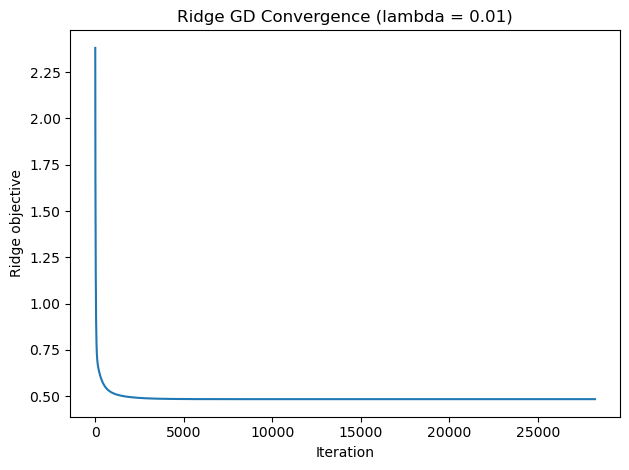

In [5]:
lam = 1e-2
eta = 0.04

# to compare with w from closed
w_closed = ridge_regression(Phi, t, lam)

# initialize
w = np.zeros(d + 1)
losses = [loss(w,Phi, t, lam)]

for iteration in range(1, 1_000_001):
    w = w - eta * gradient(w, t, lam)
    losses.append(loss(w,Phi, t, lam))

    rel_error = np.linalg.norm(w - w_closed) / np.linalg.norm(w_closed)

    if rel_error < 1e-6:
        break

print("GD Verification")
print("Iterations:", iteration)
print("Relative error:", rel_error)

print("cond(Phi.T @ Phi):", np.linalg.cond(Phi.T @ Phi))
print("cond(Phi.T @ Phi + lambda I):",
      np.linalg.cond(Phi.T @ Phi + lam * np.eye(d + 1)))


plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Ridge objective")
plt.title("Ridge GD Convergence (lambda = 0.01)")
plt.tight_layout()
plt.savefig(f"{OUT}/ridge_gd_convergence.png")
plt.show()

Batch GD matches the closed-form solution (relative error < 1e-6) after 28,227 iterations. The ridge penalty dramatically improves conditioning — cond(ΦᵀΦ) ≈ 2.3×10¹⁴ drops to cond(ΦᵀΦ + λI) ≈ 2.0×10³ — which is why plain GD is tractable here even though it would be hopeless on the unregularized objective.

Best lambda: 1.7782794100389227e-07
Minimum test RMSE: 0.11457749791147338
Lambda interval: 3.162277660168379e-08 to 0.0001


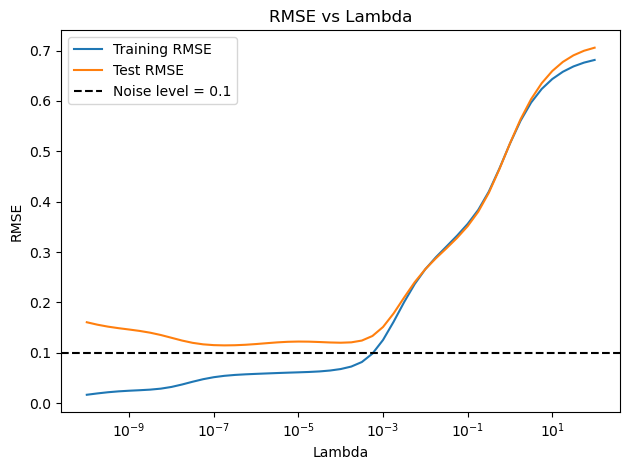

In [6]:
best_idx = np.argmin(test_rmse)
lam_star = lams[best_idx]
min_rmse = test_rmse[best_idx]

valid_lams = lams[test_rmse <= 1.05 * min_rmse]

print("Best lambda:", lam_star)
print("Minimum test RMSE:", min_rmse)
print("Lambda interval:", valid_lams[0], "to", valid_lams[-1])

plt.plot(lams, train_rmse, label="Training RMSE")
plt.plot(lams, test_rmse, label="Test RMSE")
plt.axhline(0.1, linestyle="--", color="black", label="Noise level = 0.1")

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("RMSE")
plt.title("RMSE vs Lambda")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/ridge_rmse_sweep.png")
plt.show()

The minimum is flat: test RMSE stays within 5% of its minimum (0.1146) over roughly three orders of magnitude in λ (≈3×10⁻⁸ to 1×10⁻⁴). Below this range the model overfits (train RMSE keeps dropping while test RMSE stays flat/rises); above it, both RMSEs climb together as the penalty increasingly underfits.

Lambda = 1.00e-10, ||w||2 = 3.979220e+03
Lambda = 1.78e-07, ||w||2 = 1.244946e+02
Lambda = 1.00e-02, ||w||2 = 5.107943e+00


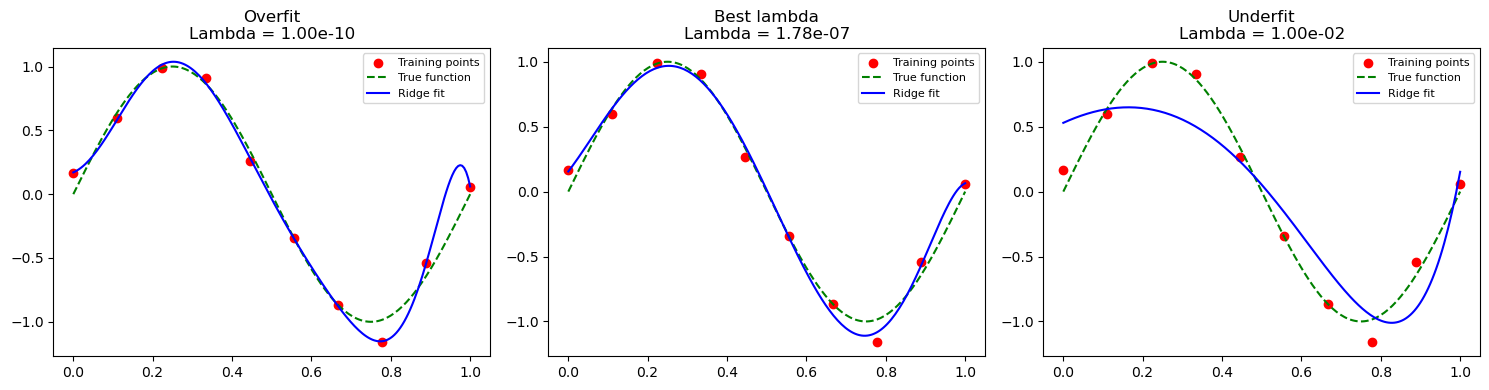

In [7]:
x_dense = np.linspace(0, 1, 200)
lambdas_plot = [1e-10, lam_star, 1e-2]
titles = ["Overfit", "Best lambda", "Underfit"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, lam, title in zip(axes, lambdas_plot, titles):
    w = ridge_regression(Phi, t, lam)
    y_dense = prediction(x_dense, w, d)

    ax.scatter(x, t, color="red", label="Training points")
    ax.plot(x_dense, np.sin(2 * np.pi * x_dense),
            "g--", label="True function")
    ax.plot(x_dense, y_dense, "b-", label="Ridge fit")

    ax.set_title(f"{title}\nLambda = {lam:.2e}")
    ax.legend(fontsize=8)

    print(f"Lambda = {lam:.2e}, ||w||2 = {np.linalg.norm(w):.6e}")

plt.tight_layout()
plt.savefig(f"{OUT}/ridge_fitted_curves.png")
plt.show()